# 01 - Problem framing, data and EDA
**Project:** Bus Passenger-Demand Forecasting (Algions AI Labs internship assessment)

## Framing
| Item | Definition |
|---|---|
| Business decision | How many buses / which bus size to schedule for each departure |
| Prediction unit | one scheduled trip = route + departure date/time |
| Target | `passengers` boarded (<= seat capacity) |
| Horizon / point in time | forecast issued **00:00, 7 days before the departure date**; only trips up to *departure date - 8 days* are visible |
| Data | **synthetic** generator (`busdemand/data_generator.py`), 12 routes, 2022-2025, no personal data |

The notebook walks through data quality, cleaning, exploratory analysis and the leakage audit.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Image
from busdemand import config as C
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25})

## 1. Raw data

In [2]:
raw = pd.read_csv(C.RAW_TRIPS)
print(raw.shape)
display(raw.head())
display(raw.dtypes.to_frame("dtype").T)
display(raw.isna().sum().to_frame("missing").T)

(101212, 8)


,trip_id,route_id,origin,destination,distance_km,departure_datetime,capacity_seats,passengers
0,R07-20240626-1830,R07,Patiala,Chandigarh,65.0,2024-06-26 18:30:00,40.0,20.0
1,R09-20231023-1730,R09,Chandigarh,Manali,310.0,2023-10-23 17:30:00,45.0,26.0
2,R11-20250403-1900,R11,Jalandhar,Ludhiana,60.0,2025-04-03 19:00:00,45.0,22.0
3,R05-20231225-0630,R05,Amritsar,Jalandhar,80.0,2023-12-25 06:30:00,40.0,25.0
4,R04-20220123-1900,R04,Amritsar,Delhi,450.0,2022-01-23 19:00:00,45.0,42.0


,trip_id,route_id,origin,destination,distance_km,departure_datetime,capacity_seats,passengers
dtype,str,str,str,str,float64,str,float64,float64


,trip_id,route_id,origin,destination,distance_km,departure_datetime,capacity_seats,passengers
missing,0,0,0,0,303,0,605,808


## 2. Data-quality checks and cleaning
The raw export deliberately contains duplicates, missing values and impossible values (more passengers than seats, negative counts).

,value
rows_raw,101212
bad_datetime_rows_dropped,0
duplicates_dropped,403
distance_filled,302
capacity_filled,604
impossible_passengers_set_nan,313
rows_without_valid_target,1117
outliers_flagged_not_removed,700
sold_out_share,0.07
rows_clean,100809


,before,after
distance_km,303,0
capacity_seats,605,0
passengers,808,1117


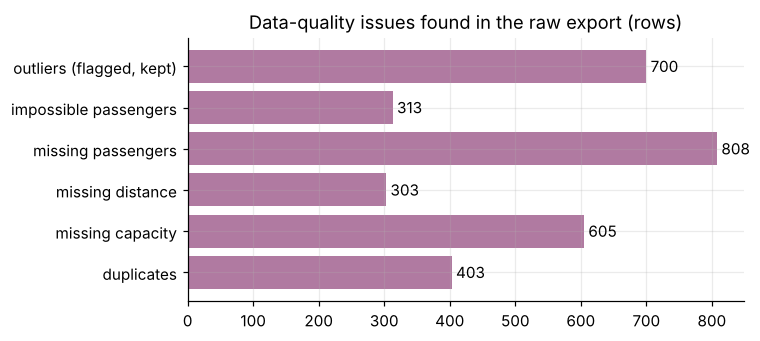

In [3]:
from busdemand.data_quality import clean_trips
clean, rep = clean_trips(raw)
display(pd.Series({k: v for k, v in rep.items() if not isinstance(v, dict)}).to_frame("value"))
display(pd.DataFrame({"before": rep["missing_before"], "after": rep["missing_after"]}))
Image(str(C.FIGURES / "eda_data_quality.png"))

Cleaning rules: drop duplicate `trip_id`; fill `distance_km` from the route master; fill `capacity_seats` with the most common capacity of the same route+slot; set impossible passenger counts to missing; rows without a valid target are excluded from modelling (they stay in the calendar). **Outliers are flagged, not removed** - most are genuine disruptions that the forecast tool must be honest about.

## 3. Target distribution and censoring

mean passengers: 26.0 | mean occupancy: 0.589 | sold-out share: 0.07


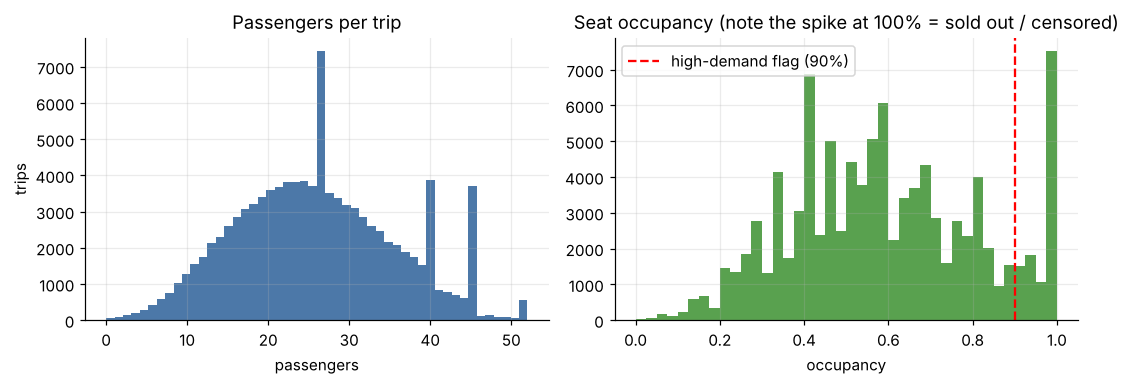

In [4]:
ok = clean[clean.valid_target]
print("mean passengers:", ok.passengers.mean().round(1), "| mean occupancy:", ok.occupancy.mean().round(3), "| sold-out share:", ok.sold_out.mean().round(3))
Image(str(C.FIGURES / "eda_target_distribution.png"))

**Observation:** the spike at 100 % occupancy is *censoring*: when a bus sells out we only see the seat count, not the true demand. The model therefore forecasts **boarded passengers**, and the app reports a sell-out-risk flag instead of pretending to know unconstrained demand.

## 4. Patterns: time of day, weekday, season, route

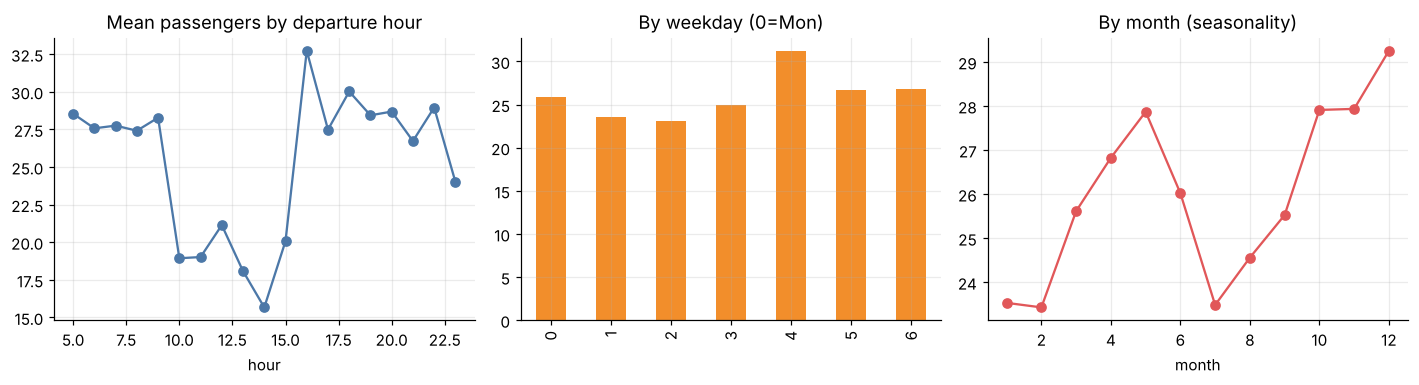

In [5]:
Image(str(C.FIGURES / "eda_patterns.png"))

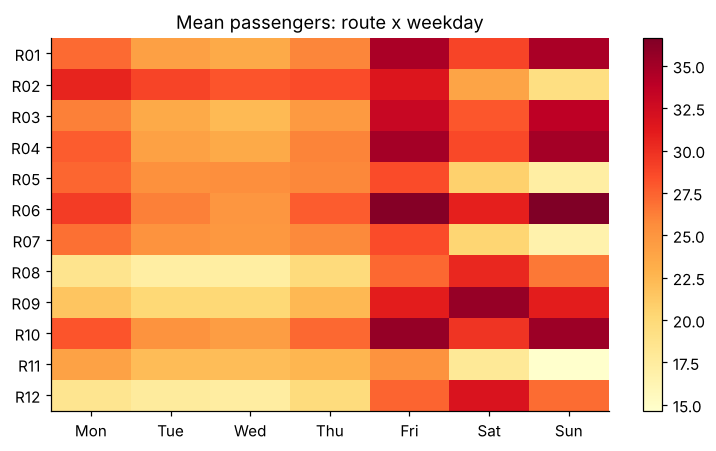

In [6]:
Image(str(C.FIGURES / "eda_route_weekday_heatmap.png"))

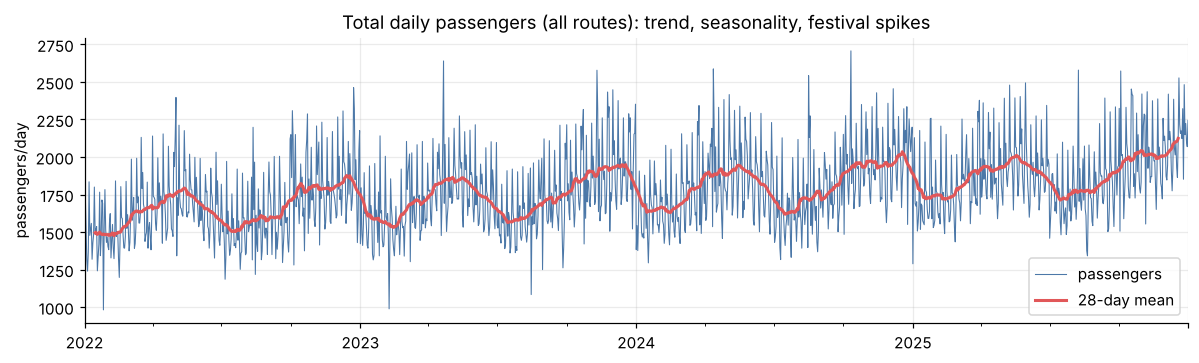

In [7]:
Image(str(C.FIGURES / "eda_daily_total.png"))

## 5. Holiday effect

In [8]:
from busdemand.holidays_cal import holiday_table
t = holiday_table(ok["date"])
ok2 = ok.reset_index(drop=True).assign(**t.to_dict("list"))
grp = np.where(ok2.is_holiday == 1, "holiday", np.where(ok2.days_to_next_holiday == 1, "day before holiday", np.where(ok2.days_since_prev_holiday == 1, "day after holiday", "normal day")))
display(ok2.assign(day_type=grp).groupby("day_type").occupancy.agg(["mean", "count"]).round(3))

,mean,count
day_type,,
day after holiday,0.650,3209
day before holiday,0.722,3208
holiday,0.513,3219
normal day,0.585,90056


## 6. Outliers vs. known disruptions

In [9]:
events = pd.read_csv(C.EVENTS_CSV, parse_dates=["start_date", "end_date"])
flag = pd.Series(False, index=clean.index)
for _, e in events.iterrows():
    flag |= (clean.route_id == e.route_id) & (clean.date >= e.start_date) & (clean.date <= e.end_date)
print("trips on disruption days (generator ground truth):", int(flag.sum()))
print("flagged outliers:", int(clean.outlier_flag.sum()), "| of which on disruption days:", int((clean.outlier_flag & flag).sum()))
display(events.head())

trips on disruption days (generator ground truth): 1011
flagged outliers: 700 | of which on disruption days: 140


,route_id,start_date,end_date,demand_multiplier
0,R01,2022-06-30,2022-07-01,0.17
1,R01,2024-06-17,2024-06-17,0.36
2,R01,2022-09-11,2022-09-13,0.27
3,R01,2025-03-23,2025-03-23,0.39
4,R01,2025-08-08,2025-08-08,0.47


## 7. Leakage analysis
* **Not used as inputs:** `passengers` of the trip itself, occupancy, sold-out flag, rain/weather, disruption events (none of these are known 7 days ahead).
* **History features** (`lag1..lag4`, `lag_mean4`, `route_mean_28d`, ...) read only trips on or before `departure_date - 8 days`.
* Calendar and holiday features are known months in advance, so they are legitimate.
* Chronological split: train <= 2025-06-30 < validation <= 2025-09-30 < test.

Automated audit (also run in `pytest`):

In [10]:
from busdemand import leakage_audit
audit = leakage_audit.run(clean, write=False)
display(pd.Series({k: v["passed"] for k, v in audit.items() if isinstance(v, dict)}).to_frame("passed"))
print(json.dumps(audit["chronological_split"], indent=1))

,passed
forbidden_inputs,True
chronological_split,True
future_invariance,True
sensitive_data,True


{
 "passed": true,
 "train": [
  "2022-01-01",
  "2025-06-30"
 ],
 "validation": [
  "2025-07-01",
  "2025-09-30"
 ],
 "test": [
  "2025-10-01",
  "2025-12-31"
 ],
 "rows": {
  "train": 87147,
  "validation": 6276,
  "test": 6269
 }
}


## 8. Feature list

In [11]:
from busdemand.features import NUM_FEATURES, CAT_FEATURES
print("numeric:", NUM_FEATURES); print("categorical:", CAT_FEATURES)

numeric: ['hour_decimal', 'is_weekend', 'is_peak_hour', 'is_holiday', 'is_major_festival', 'days_to_next_holiday', 'days_since_prev_holiday', 'next_holiday_major', 'doy_sin', 'doy_cos', 'distance_km', 'capacity_seats', 'lag1', 'lag2', 'lag3', 'lag4', 'lag_mean4', 'lag_occ_mean4', 'route_mean_28d', 'route_occ_28d', 'n_lags_available']
categorical: ['route_id', 'dow', 'season']


## Take-aways
1. Demand is driven by **route, time of day, weekday, season and holidays**, and is strongly autocorrelated at the same route/slot/weekday.
2. About **7 %** of trips are sold out, so observed counts under-state demand on the busiest trips.
3. Data issues were found and handled with documented, reversible rules; outliers are kept because they represent real disruptions.